# Diabetes 130-US Hospitals: 30-day readmission prediction

**Goal:** predict whether a diabetic inpatient will be readmitted **within 30 days** of discharge.

This notebook covers:
1. Data preparation and cleaning
2. Exploratory data analysis (EDA) and feature importance
3. Model selection and hyper-parameter tuning (see the second half)

Data: UCI *Diabetes 130-US hospitals for years 1999-2008* (101,766 encounters, 50 columns).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import load_data, prepare_features, icd9_group, MED_COLS, NUM_COLS, CAT_COLS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

raw = pd.read_csv("data/diabetic_data.csv", na_values="?", keep_default_na=False)
print(raw.shape)
raw.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1. Data overview

In [2]:
raw.dtypes.value_counts()

object    37
int64     13
Name: count, dtype: int64

In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


### Missing values
Missing values are encoded as `?` in the raw file (read as NaN above).

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64


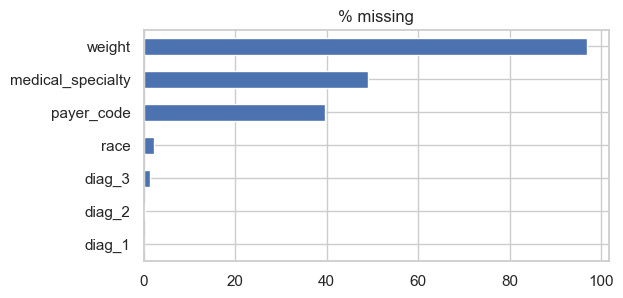

In [4]:
miss = raw.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
print(miss.round(2))
miss.plot.barh(figsize=(6, 3), title="% missing")
plt.gca().invert_yaxis(); plt.show()

* `weight` is 97% missing -> **drop**.
* `payer_code` (40%) and `medical_specialty` (49%) -> keep, missing becomes an explicit `unknown` category.
* `race`, `diag_1..3` have few missing values -> `unknown` category as well.

### Constant / useless columns

In [5]:
nun = raw.nunique().sort_values()
print(nun.head(8))
print("encounter_id unique:", raw.encounter_id.is_unique, "| patients:", raw.patient_nbr.nunique())

citoglipton                 1
examide                     1
acetohexamide               2
glipizide-metformin         2
tolbutamide                 2
troglitazone                2
metformin-rosiglitazone     2
glimepiride-pioglitazone    2
dtype: int64
encounter_id unique: True | patients: 71518


`examide` and `citoglipton` have a single value -> no information. `encounter_id` is only an identifier.
`patient_nbr` is used only for **grouping** the train/validation/test split, because about 25% of patients appear more than once (together ~46% of all encounters) (otherwise the same patient could leak across splits).

## 2. Target variable

readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64


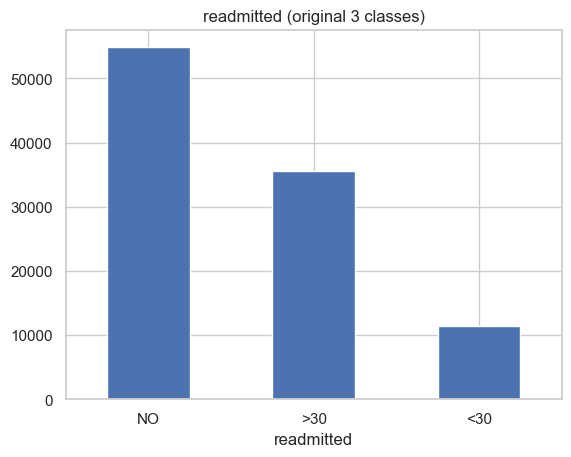

In [6]:
print(raw.readmitted.value_counts(normalize=True).round(3))
raw.readmitted.value_counts().plot.bar(title="readmitted (original 3 classes)", rot=0)
plt.show()

We turn this into a binary problem: `target = 1` if `readmitted == '<30'` (the costly early readmission), otherwise 0.

Encounters whose discharge disposition is *expired* or *hospice* can never be readmitted, so we remove them (they would only add noise).

In [7]:
df = load_data()
print("rows before:", len(raw), "after removing expired/hospice:", len(df))
print("positive rate:", df.target.mean().round(4))

rows before: 101766 after removing expired/hospice: 99343
positive rate: 0.1139


In [8]:
print(df.groupby("patient_nbr").size().value_counts().head(6).rename("encounters per patient"))

1    53649
2    10218
3     3233
4     1354
5      691
6      338
Name: encounters per patient, dtype: int64


## 3. Numeric features

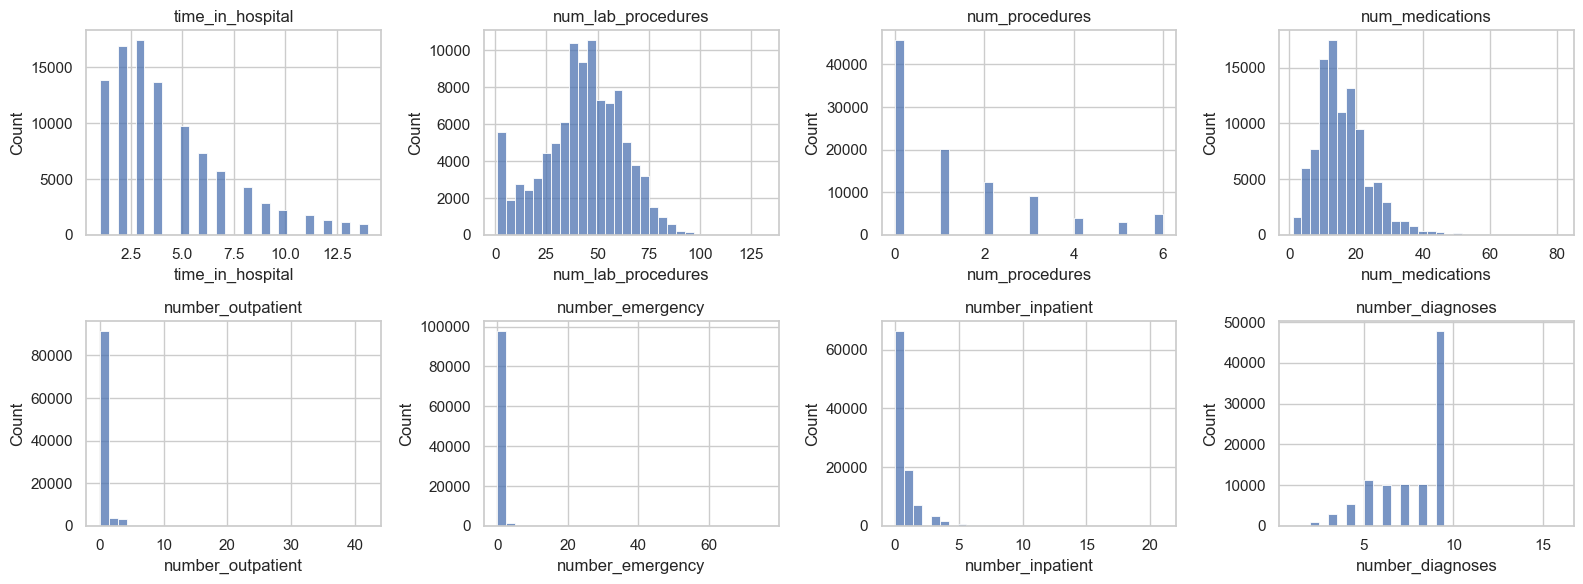

In [9]:
num_raw = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_raw):
    sns.histplot(df[c], bins=30, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

Counts of prior visits are heavily right-skewed; tree models handle this naturally and for linear models we standardise.

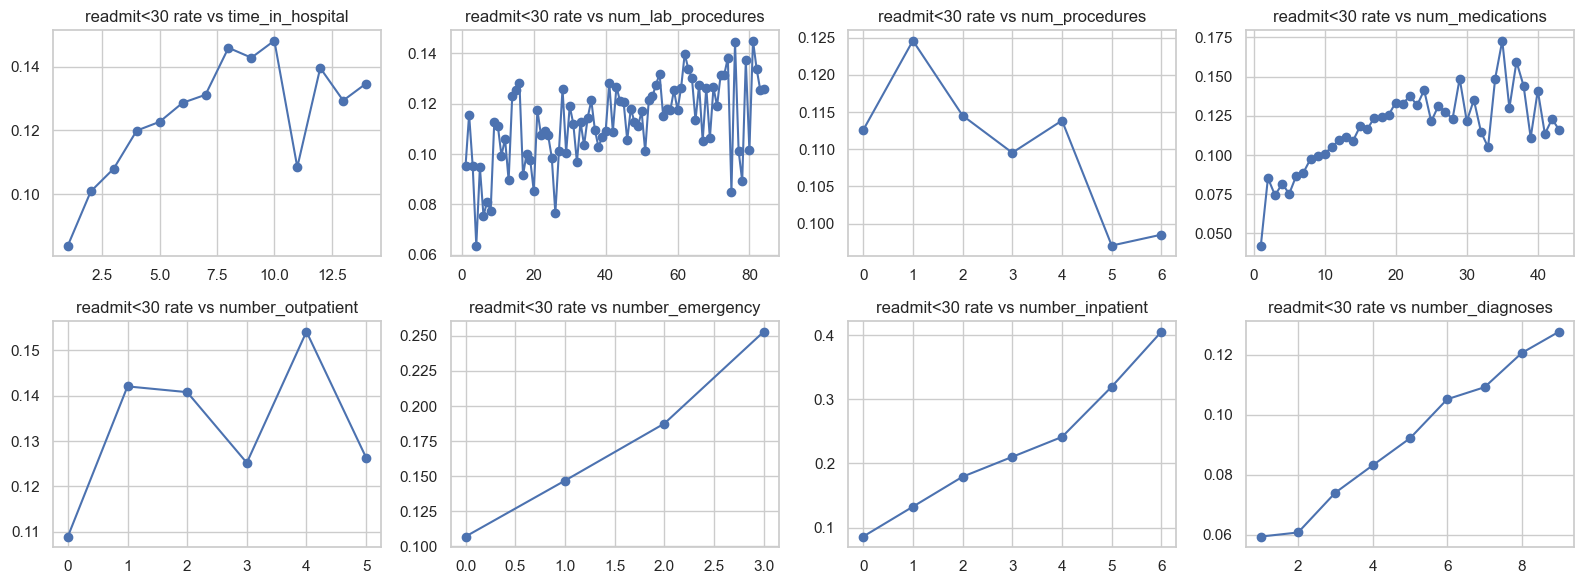

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_raw):
    g = df.assign(b=df[c].clip(upper=df[c].quantile(0.99))).groupby("b").target.agg(["mean", "size"])
    g = g[g["size"] >= 100]
    ax.plot(g.index, g["mean"], marker="o"); ax.set_title(f"readmit<30 rate vs {c}")
plt.tight_layout(); plt.show()

**`number_inpatient`** (inpatient visits in the previous year) shows the strongest monotonic relation with early readmission; `number_emergency` and `number_diagnoses` also increase the risk.

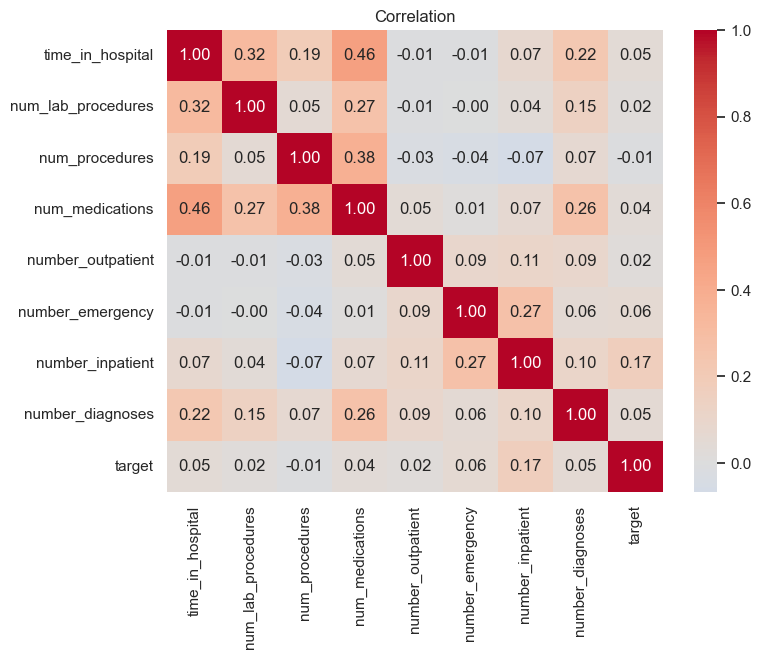

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_raw + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation"); plt.show()

## 4. Categorical features

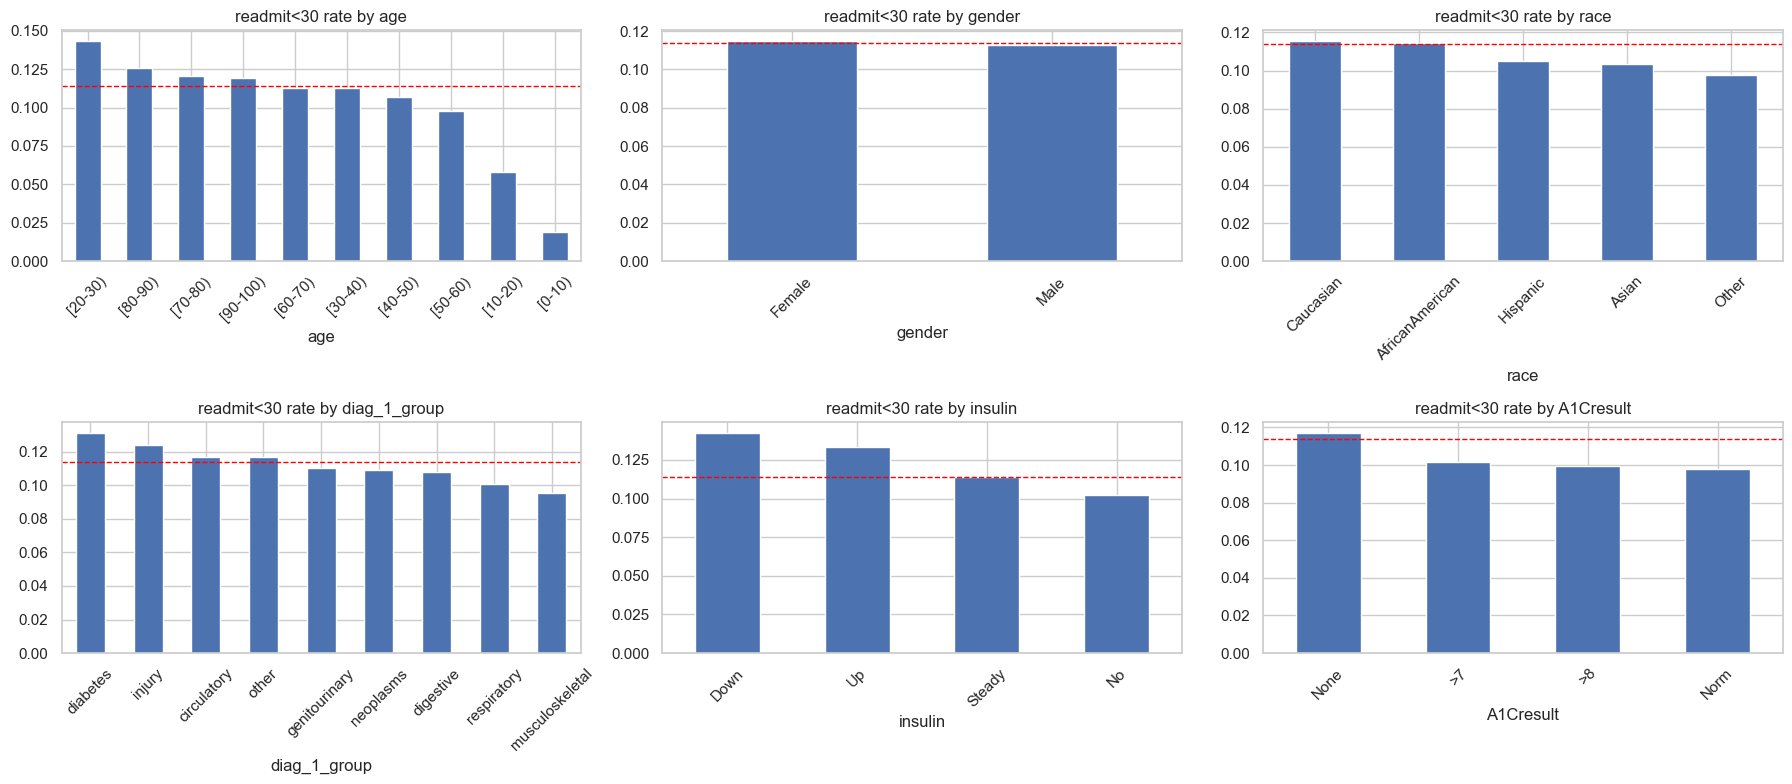

In [12]:
def rate_plot(col, data=df, top=None, ax=None, rot=0):
    g = data.groupby(col).target.agg(["mean", "size"])
    g = g[g["size"] >= 100].sort_values("mean", ascending=False)
    if top: g = g.head(top)
    ax = ax or plt.gca()
    g["mean"].plot.bar(ax=ax, rot=rot)
    ax.axhline(data.target.mean(), color="red", ls="--", lw=1)
    ax.set_title(f"readmit<30 rate by {col}")

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
df["diag_1_group"] = df.diag_1.map(icd9_group)
for ax, c in zip(axes.ravel(), ["age", "gender", "race", "diag_1_group", "insulin", "A1Cresult"]):
    rate_plot(c, ax=ax, rot=45)
plt.tight_layout(); plt.show()

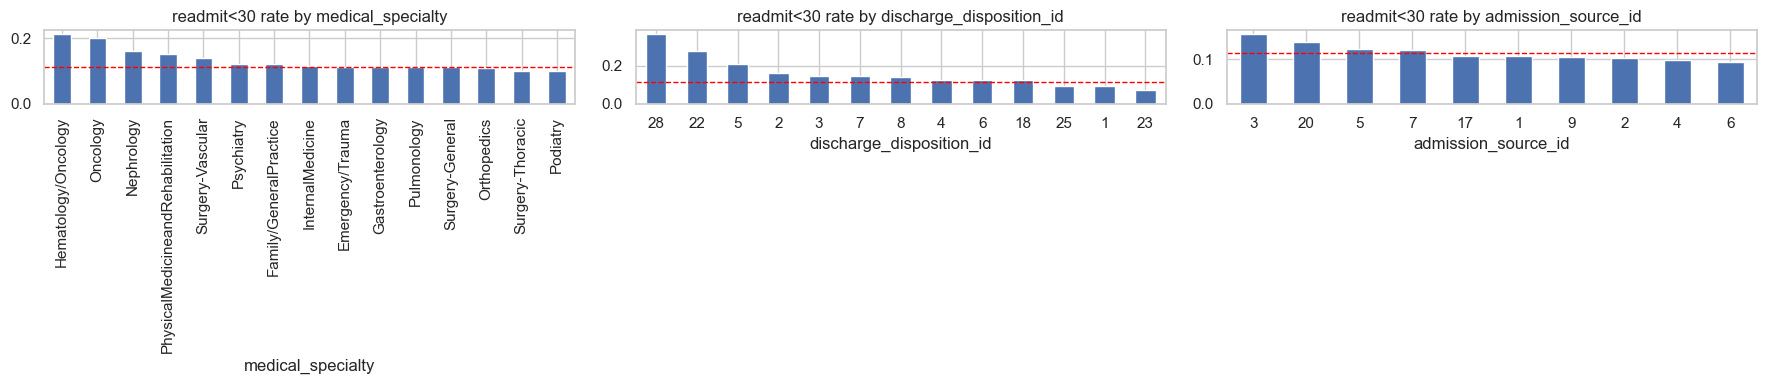

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
rate_plot("medical_specialty", top=15, ax=axes[0], rot=90)
rate_plot("discharge_disposition_id", ax=axes[1])
rate_plot("admission_source_id", ax=axes[2])
plt.tight_layout(); plt.show()

Observations: risk rises with age up to ~[80-90), circulatory/diabetes/respiratory primary diagnoses differ visibly, and discharge destination matters a lot (e.g. transfers to other facilities).
`diag_1..3` have ~700 distinct ICD-9 codes, so we group them into ~9 disease families with `icd9_group()`.

## 5. Feature importance (before modelling)

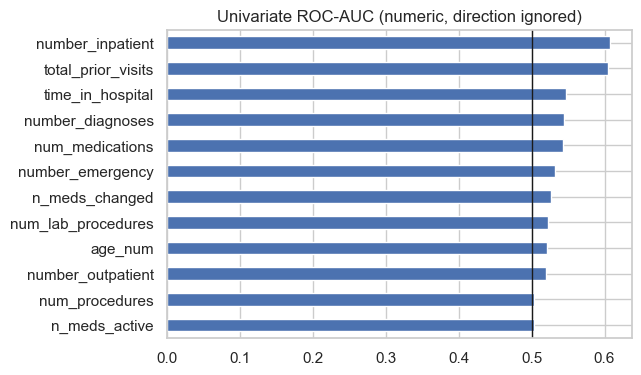

In [14]:
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif

X = prepare_features(df)
y = df.target

# (a) univariate ROC-AUC of every numeric feature
auc = {c: roc_auc_score(y, X[c]) for c in NUM_COLS}
auc = pd.Series(auc)
(auc - 0.5).abs().add(0.5).sort_values().plot.barh(figsize=(6, 4), title="Univariate ROC-AUC (numeric, direction ignored)")
plt.axvline(0.5, color="k", lw=1); plt.show()

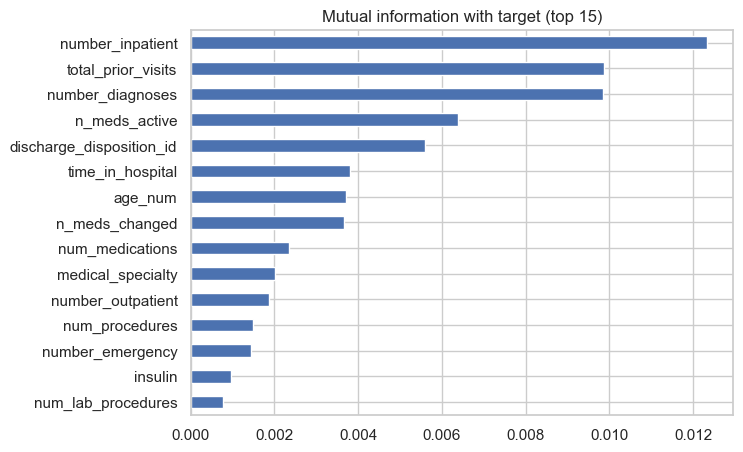

In [15]:
# (b) mutual information for all features (categoricals ordinal-encoded)
Xo = X.copy()
for c in CAT_COLS:
    Xo[c] = Xo[c].astype("category").cat.codes
mi = mutual_info_classif(Xo, y, discrete_features=[c in CAT_COLS for c in Xo.columns], random_state=1)
mi = pd.Series(mi, index=Xo.columns).sort_values(ascending=False)
mi.head(15).sort_values().plot.barh(figsize=(7, 5), title="Mutual information with target (top 15)")
plt.show()

**Takeaways**

* Dataset is **imbalanced** (~11% positives) -> accuracy is misleading; we use **ROC-AUC** (main) and **PR-AUC**.
* Most informative features: prior inpatient / emergency visits (`number_inpatient`, `total_prior_visits`), discharge disposition, number of diagnoses, time in hospital, number of medications, age.
* The signal is weak overall (this is a hard, noisy problem; published models reach ROC-AUC ~0.65-0.70), so we should not expect big numbers.
* Dropped: `weight`, `encounter_id`, `examide`, `citoglipton`, and the raw `readmitted`/`diag_*` columns (replaced by `target` and diagnosis groups). Final feature engineering is implemented in `features.py`.